# Contrôle de la génération des données
Vérifie que les 5 signaux métier injectés sont visibles dans les données propres (vérité terrain).

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

VERITE = Path("../data/reference/verite")

commandes = pd.read_csv(VERITE / "fact_commande.csv",
                        parse_dates=["date_commande", "date_promise", "date_livraison"])
produits = pd.read_csv(VERITE / "dim_produit.csv")
lots = pd.read_csv(VERITE / "fact_lot.csv")
deviations = pd.read_csv(VERITE / "fact_deviation.csv")

liv = commandes[commandes["statut_commande"] == "livrée"].merge(
    produits[["sku", "gamme", "complexite"]], on="sku")
liv["a_l_heure"] = (liv["date_livraison"] - liv["date_promise"]).dt.days <= 2
liv["otif"] = liv["a_l_heure"] & (liv["qte_conforme"] >= 0.98 * liv["qte_commandee"])
liv["mois"] = liv["date_promise"].dt.to_period("M").dt.to_timestamp()
print(f"{len(liv)} commandes livrées, OTIF global : {liv['otif'].mean():.1%}")

5821 commandes livrées, OTIF global : 84.5%


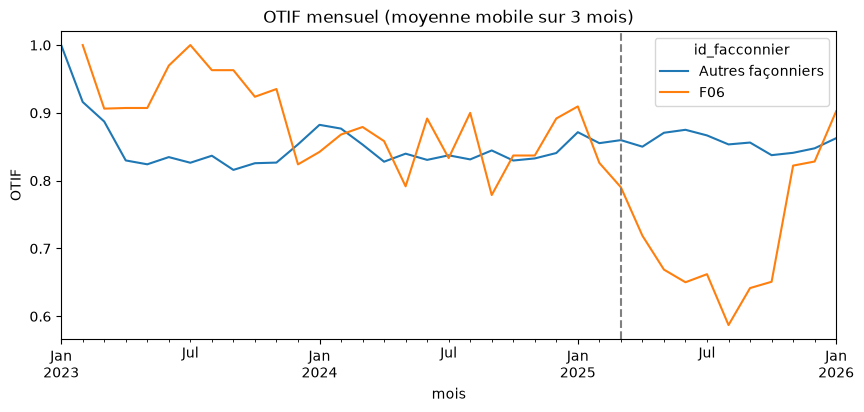

In [12]:
groupe = liv["id_facconnier"].where(liv["id_facconnier"] == "F06", "Autres façonniers")
otif_mensuel = liv.groupby(["mois", groupe])["otif"].mean().unstack()

ax = otif_mensuel.rolling(3, min_periods=1).mean().plot(
    figsize=(10, 4), title="OTIF mensuel (moyenne mobile sur 3 mois)")
ax.axvline(pd.Timestamp("2025-03-01"), linestyle="--", color="grey")
ax.set_ylabel("OTIF")
plt.show()

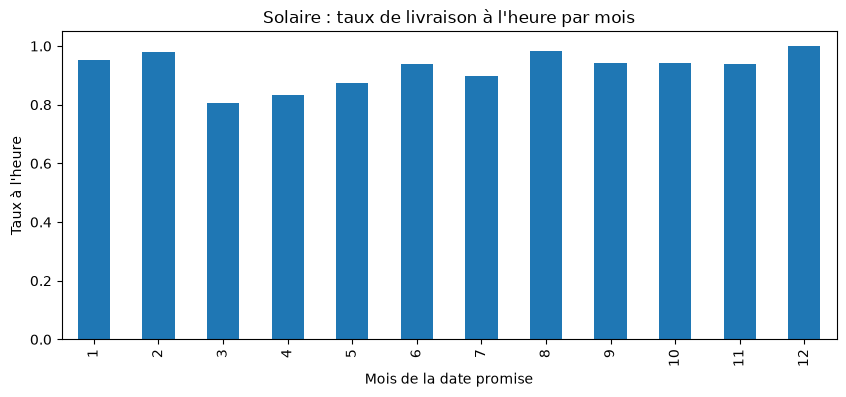

In [13]:
solaire = liv[liv["gamme"] == "Solaire"]
par_mois = solaire.groupby(solaire["date_promise"].dt.month)["a_l_heure"].mean()

ax = par_mois.plot.bar(figsize=(10, 4), title="Solaire : taux de livraison à l'heure par mois")
ax.set_xlabel("Mois de la date promise")
ax.set_ylabel("Taux à l'heure")
plt.show()

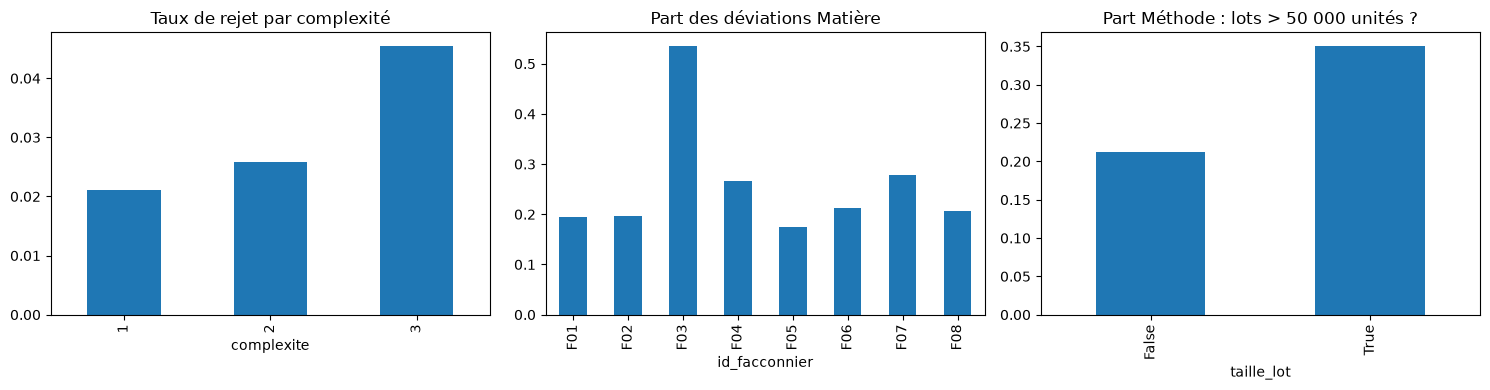

In [14]:
lc = (lots.merge(commandes[["id_commande", "sku", "id_facconnier"]], on="id_commande")
          .merge(produits[["sku", "complexite"]], on="sku"))
dv = deviations.merge(lc[["id_lot", "id_facconnier", "taille_lot"]], on="id_lot")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lc["statut_lot"].eq("rejeté").groupby(lc["complexite"]).mean().plot.bar(
    ax=axes[0], title="Taux de rejet par complexité")
dv["categorie_6m_verite"].eq("Matière").groupby(dv["id_facconnier"]).mean().plot.bar(
    ax=axes[1], title="Part des déviations Matière")
dv["categorie_6m_verite"].eq("Méthode").groupby(dv["taille_lot"] > 50000).mean().plot.bar(
    ax=axes[2], title="Part Méthode : lots > 50 000 unités ?")
plt.tight_layout()
plt.show()

In [15]:
RAW = Path("../data/raw/facconniers")

f04 = pd.read_excel(RAW / "F04_atlantique_formulation.xlsx")
display(f04.head(3))

f06 = pd.read_excel(RAW / "F06_wisla_contract_manufacturing.xlsx", sheet_name=None)
print(f"F06 : {len(f06)} onglets")

f05 = pd.read_excel(RAW / "F05_valencia_cosmetic_partners.xlsx")
display(f05[f05["Cantidad pedida"] < 1000].head(3))

,num_cde,ref_art,fourn,dt_cde,dt_prom,dt_liv,qte_cde,qte_liv,qte_conf,pu
0,CMD-2023-00002,DL-SO-005,ATLANTIQUE FORMUL.,44928,44963,44962.0,62000,62000.0,62000.0,2.682
1,CMD-2023-00003,DL-HY-004,Atlantique Formulations,44928,44961,44956.0,52500,52500.0,52500.0,4.036
2,CMD-2023-00008,DL-SV-010,Atl. Formulation,44928,44964,44966.0,27500,27500.0,27500.0,3.076


F06 : 36 onglets


,Nº pedido,Referencia,Proveedor,Fecha pedido,Fecha prometida,Fecha entrega,Cantidad pedida,Cantidad entregada,Cantidad conforme,Precio unitario
190,CMD-2024-00002,DL-BB-003,VALENCIA COSMETIC,2024-01-01,2024-02-10,2024-02-11,54.5,54.5,54.5,"4,501"
191,CMD-2024-00006,DL-SV-002,Valencia CP,2024-01-02,2024-02-08,2024-02-08,57.5,57.5,57.5,"4,132"
192,CMD-2024-00006,DL-SV-002,VALENCIA COSMETIC,2024-01-02,2024-02-08,2024-02-08,57.5,57.5,57.5,"4,132"


## Ce qu'on retient

Les 5 signaux injectés sont bien visibles dans les données propres :

- **Dérive de F06** : son taux de livraison à l'heure passe de 92 % à 78 % à partir de mars 2025, alors que les autres façonniers restent stables.
- **Saisonnalité du Solaire** : 84 % de livraisons à l'heure en mars-mai, contre 95 % le reste de l'année, ce qui correspond au pic de charge avant l'été.
- **Effet de la complexité** : les produits les plus complexes sont rejetés deux fois plus souvent (4,6 % contre 2,1 à 2,6 %).
- **Profil qualité de F03** : plus de la moitié de ses déviations (54 %) concernent la matière, contre 18 à 28 % chez les autres façonniers.
- **Effet de la taille de lot** : les lots de plus de 50 000 unités ont davantage de déviations liées à la méthode (35 % contre 21 %).

Ces résultats servent de référence : les analyses de la phase 3, menées sur les données nettoyées par Alteryx, devront retrouver les mêmes ordres de grandeur.